# SafeRoute NCR – Traffic-fine risk model
Generative-AI project notebook: load the dataset → explore → train & compare models → export predictions for the website.

**Run order:** just *Run All*. Needs `pandas numpy scikit-learn matplotlib joblib` (`pip install pandas numpy scikit-learn matplotlib joblib`).

In [1]:
import os, json, subprocess, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

CSV = "traffic_fines_ncr.csv"
if not os.path.exists(CSV):                       # build the dataset if it is missing
    subprocess.run([sys.executable, "generate_traffic_fines_ncr.py"], check=True)
df = pd.read_csv(CSV, parse_dates=["date"])
print(df.shape); df.head()

(60000, 32)


,checkpoint_id,checkpoint_name,latitude,longitude,road_type,speed_limit_kmph,is_near_metro,police_presence,camera_density,traffic_density,...,total_fine_amount_inr,top_violation,helmet_violations,no_licence_violations,drunk_driving_violations,speeding_violations,signal_jumping_violations,wrong_parking_violations,no_documents_violations,fine_risk_score
0,CP01,Connaught Place (Rajiv Chowk),28.6315,77.2167,signal,50,1,0.9,0.92,0.95,...,0,none,0,0,0,0,0,0,0,0.00
1,CP01,Connaught Place (Rajiv Chowk),28.6315,77.2167,signal,50,1,0.9,0.92,0.95,...,60000,helmet,8,2,0,2,7,4,2,38.46
2,CP01,Connaught Place (Rajiv Chowk),28.6315,77.2167,signal,50,1,0.9,0.92,0.95,...,43500,helmet,7,1,0,2,5,1,4,30.77
3,CP01,Connaught Place (Rajiv Chowk),28.6315,77.2167,signal,50,1,0.9,0.92,0.95,...,90000,signal_jumping,7,3,2,3,8,4,3,46.15
4,CP01,Connaught Place (Rajiv Chowk),28.6315,77.2167,signal,50,1,0.9,0.92,0.95,...,112000,signal_jumping,6,4,1,5,13,4,3,55.38


## 1. Explore the data

weather          0.0096
temperature_c    0.0102
dtype: float64


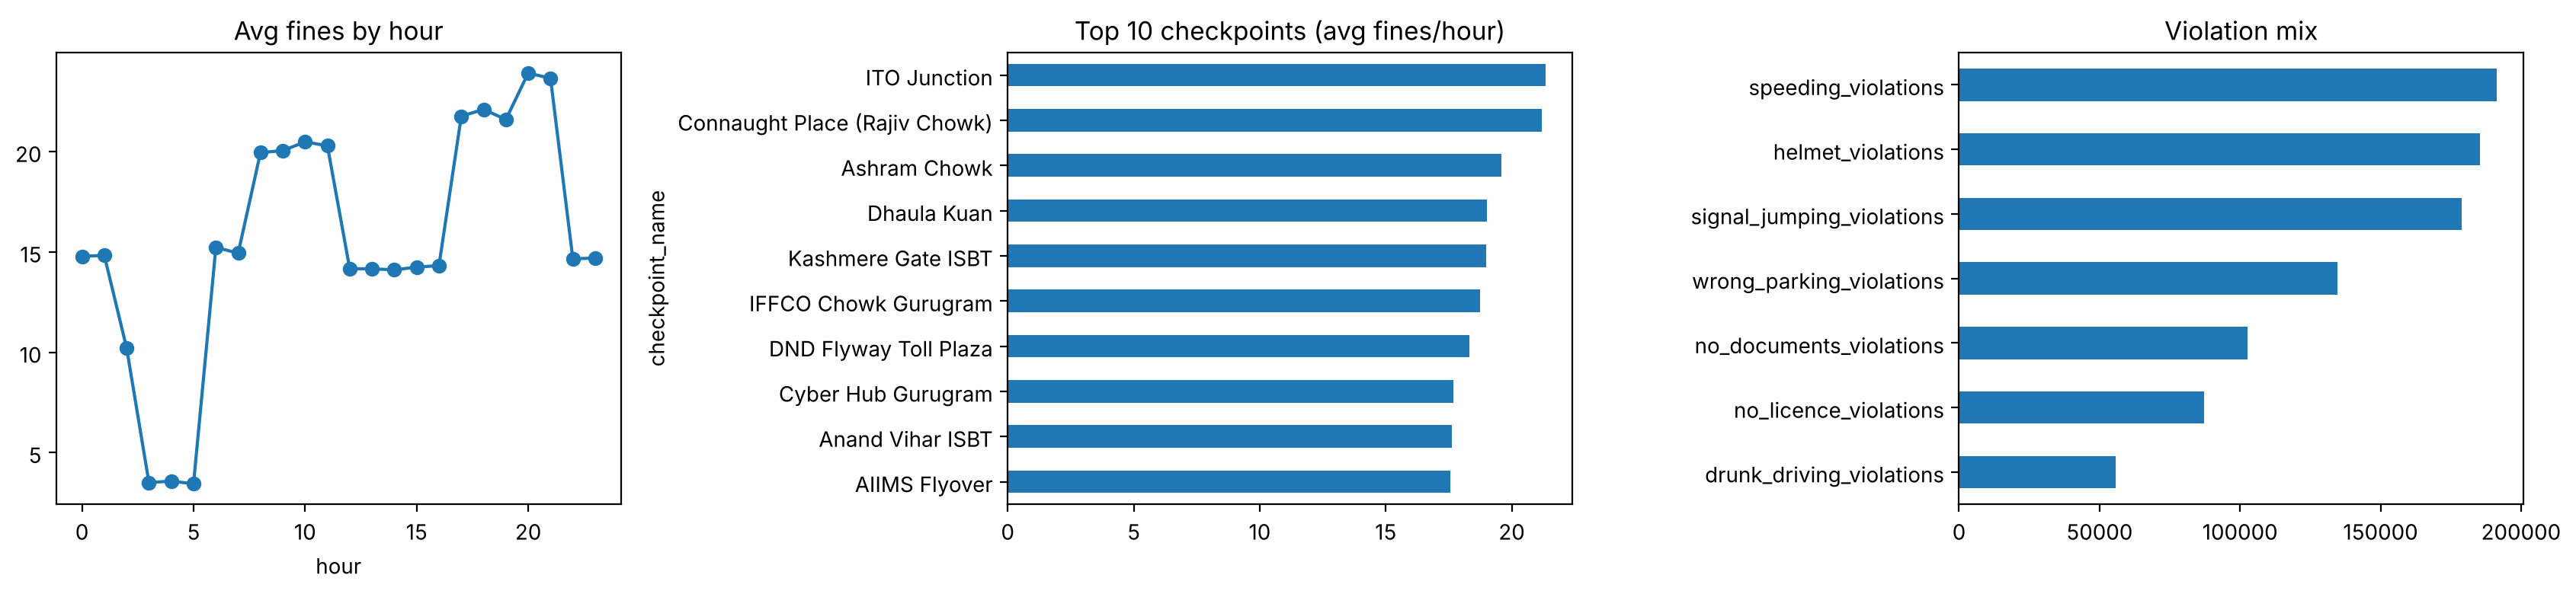

In [2]:
print(df.isna().mean()[lambda s: s>0].round(4))
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
df.groupby("hour")["fines_issued"].mean().plot(ax=ax[0], marker="o", title="Avg fines by hour")
df.groupby("checkpoint_name")["fines_issued"].mean().nlargest(10).sort_values().plot.barh(ax=ax[1], title="Top 10 checkpoints (avg fines/hour)")
df[[c for c in df.columns if c.endswith("_violations")]].sum().sort_values().plot.barh(ax=ax[2], title="Violation mix")
plt.tight_layout(); plt.show()

## 2. Features and a time-based split
Train on Jan–Apr, test on May–Jun, so the score reflects predicting *future* weeks (no leakage).

In [3]:
d = df.copy()
d["hour_sin"] = np.sin(2*np.pi*d["hour"]/24); d["hour_cos"] = np.cos(2*np.pi*d["hour"]/24)
d["is_night"] = d["hour"].isin([22,23,0,1,2]).astype(int)
d["is_peak"]  = d["hour"].isin([8,9,10,11,17,18,19,20,21]).astype(int)
NUM = ["latitude","longitude","speed_limit_kmph","is_near_metro","police_presence","camera_density","traffic_density",
       "hour","hour_sin","hour_cos","is_night","is_peak","day_of_week","is_weekend","is_holiday","month","temperature_c","event_nearby"]
CAT = ["road_type","weather"]
TARGET = "fines_issued"
train, test = d[d.month<=4], d[d.month>=5]
print(len(train), len(test))

39731 20269


## 3. Train and compare models

In [4]:
def prep():
    return ColumnTransformer([
        ("n", SimpleImputer(strategy="median"), NUM),
        ("c", Pipeline([("i", SimpleImputer(strategy="most_frequent")), ("o", OneHotEncoder(handle_unknown="ignore"))]), CAT)])
models = {
 "Ridge (baseline)": Ridge(alpha=1.0),
 "Random Forest": RandomForestRegressor(n_estimators=120, max_depth=14, min_samples_leaf=5, n_jobs=-1, random_state=42),
 "Gradient Boosting": HistGradientBoostingRegressor(max_depth=6, learning_rate=0.08, max_iter=300, random_state=42),
}
rows, fitted = [], {}
for name, m in models.items():
    p = Pipeline([("prep", prep()), ("model", m)]).fit(train[NUM+CAT], train[TARGET])
    pr = p.predict(test[NUM+CAT]); fitted[name] = p
    rows.append({"model": name, "MAE": mean_absolute_error(test[TARGET], pr), "R2": r2_score(test[TARGET], pr)})
res = pd.DataFrame(rows).set_index("model").round(3); res

,MAE,R2
model,,
Ridge (baseline),5.828,0.380
Random Forest,5.177,0.465
Gradient Boosting,5.023,0.495


Best model: Gradient Boosting


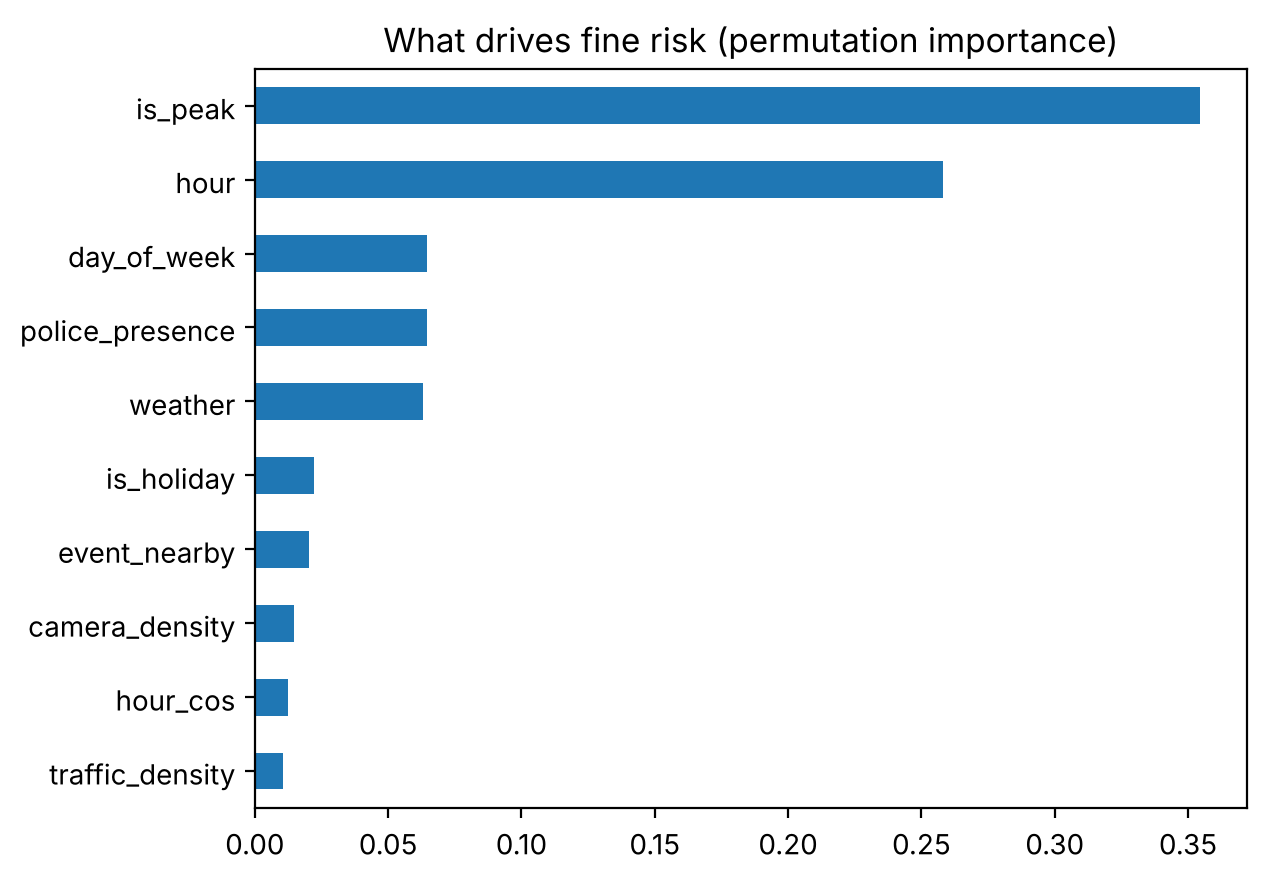

In [5]:
best_name = res["R2"].idxmax(); print("Best model:", best_name)
# refit the winner on ALL data for the final app model
final = Pipeline([("prep", prep()), ("model", models[best_name])]).fit(d[NUM+CAT], d[TARGET])
joblib.dump(final, "risk_model.joblib")
imp = permutation_importance(fitted[best_name], test[NUM+CAT].sample(5000, random_state=1), test[TARGET].loc[test[NUM+CAT].sample(5000, random_state=1).index], n_repeats=3, random_state=1, n_jobs=-1)
pd.Series(imp.importances_mean, index=NUM+CAT).sort_values().tail(10).plot.barh(title="What drives fine risk (permutation importance)"); plt.show()

## 4. Export predictions for the website
The website is static, so we pre-compute the model's expected fines for every checkpoint × day × hour (averaged over Jan–Jun, clear weather, no holiday) and save them to `website/data.js`.

In [6]:
cps = df.drop_duplicates("checkpoint_id")[["checkpoint_id","checkpoint_name","latitude","longitude","road_type","speed_limit_kmph","is_near_metro","police_presence","camera_density","traffic_density"]].reset_index(drop=True)
temp_by_hour = df.groupby("hour")["temperature_c"].median()
g = cps.merge(pd.DataFrame({"day_of_week": np.repeat(range(7),24), "hour": list(range(24))*7}), how="cross")
frames = []
for mth in range(1,7):
    x = g.copy(); x["month"]=mth; x["is_weekend"]=(x.day_of_week>=5).astype(int); x["is_holiday"]=0
    x["event_nearby"]=0; x["weather"]="clear"; x["temperature_c"]=x["hour"].map(temp_by_hour)
    x["hour_sin"]=np.sin(2*np.pi*x.hour/24); x["hour_cos"]=np.cos(2*np.pi*x.hour/24)
    x["is_night"]=x.hour.isin([22,23,0,1,2]).astype(int); x["is_peak"]=x.hour.isin([8,9,10,11,17,18,19,20,21]).astype(int)
    x["pred"]=np.clip(final.predict(x[NUM+CAT]),0,None); frames.append(x)
G = pd.concat(frames).groupby(["checkpoint_id","day_of_week","hour"], as_index=False)["pred"].mean()
p99 = float(np.percentile(G["pred"], 99))

V = ["helmet","no_licence","drunk_driving","speeding","signal_jumping","wrong_parking","no_documents"]
bands = {"night":[22,23,0,1,2,3,4,5], "morning":list(range(6,12)), "midday":list(range(12,17)), "evening":list(range(17,22))}
out = []
for _, c in cps.iterrows():
    sub = df[df.checkpoint_id==c.checkpoint_id]
    mix = {}
    for b, hs in bands.items():
        sb = sub[sub.hour.isin(hs)]; tot = max(float(sb[[f"{v}_violations" for v in V]].sum().sum()), 1.0)
        mix[b] = [round(float(sb[f"{v}_violations"].sum())/tot, 3) for v in V]
    tops = {b: V[int(np.argmax(mix[b]))] for b in bands}
    pr = G[G.checkpoint_id==c.checkpoint_id].pivot(index="day_of_week", columns="hour", values="pred").round(2).values.tolist()
    out.append({"id":c.checkpoint_id,"name":c.checkpoint_name,"lat":c.latitude,"lon":c.longitude,"road":c.road_type,"speed":int(c.speed_limit_kmph),
                "metro":int(c.is_near_metro),"police":c.police_presence,"camera":c.camera_density,"traffic":c.traffic_density,
                "avgFine":int(sub.total_fine_amount_inr.sum()/max(sub.fines_issued.sum(),1)),"top":tops,"mix":mix,"fines":pr})
payload = {"viol":V,"p99":round(p99,3),"model":best_name,"r2":float(res.loc[best_name,"R2"]),"mae":float(res.loc[best_name,"MAE"]),"checkpoints":out}
os.makedirs("website", exist_ok=True)
open("website/data.js","w").write("window.NCR = " + json.dumps(payload, separators=(",",":")) + ";")
print("Saved website/data.js –", len(out), "checkpoints, p99 =", round(p99,2))

Saved website/data.js – 40 checkpoints, p99 = 29.78


## 5. Sanity check – riskiest places on a Monday 9 am vs Saturday 11 pm

In [7]:
def top5(dow, hr):
    s = G[(G.day_of_week==dow)&(G.hour==hr)].merge(cps[["checkpoint_id","checkpoint_name"]]).nlargest(5,"pred")
    return s[["checkpoint_name","pred"]].round(1)
display(top5(0,9)); display(top5(5,23))

,checkpoint_name,pred
0,Connaught Place (Rajiv Chowk),30.5
1,ITO Junction,29.9
16,Ashram Chowk,27.1
8,Kashmere Gate ISBT,26.3
34,DND Flyway Toll Plaza,26.3


,checkpoint_name,pred
0,Connaught Place (Rajiv Chowk),22.6
1,ITO Junction,22.5
16,Ashram Chowk,21.0
8,Kashmere Gate ISBT,20.2
2,Dhaula Kuan,20.1


## 6. Next: open the website
```
cd website
python -m http.server 8000
```
then visit http://localhost:8000 (see README.md for free hosting options).